# Mortality overview across distance space (2 ambulances, max bcas only)


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

df = pd.read_csv(_root / "data_cluster/resource_grid/results.csv")
df = df[df["n_amb_r1_to_ccp"] == 1].reset_index(drop=True)

max_bcas = df["bcas_rate"].max()
df = df[df["bcas_rate"] == max_bcas].reset_index(drop=True)
print(f"Loaded {len(df)} runs (2 ambulances, bcas={max_bcas})")

POLICIES = {
    "Stovepipe": (0, 0),
    "Facility": (1, 0),
    "Ambulance": (0, 1),
    "Both": (1, 1),
}

data = {}
for label, (fac, amb) in POLICIES.items():
    sub = df[(df["facility_eligibility"] == fac) & (df["ambulance_eligibility"] == amb)]
    agg = sub.groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"])["death_rate_T1_BCAS"].mean().reset_index()
    pivot = agg.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="death_rate_T1_BCAS")
    data[label] = pivot
    print(f"{label}: {len(sub)} runs, {pivot.shape[0]}x{pivot.shape[1]} grid")

cols = data["Stovepipe"].columns.values
rows = data["Stovepipe"].index.values


Loaded 67600 runs (2 ambulances, bcas=0.07)
Stovepipe: 16900 runs, 13x13 grid
Facility: 16900 runs, 13x13 grid
Ambulance: 16900 runs, 13x13 grid
Both: 16900 runs, 13x13 grid


## Mean T1 mortality per policy (smoothed, max bcas)


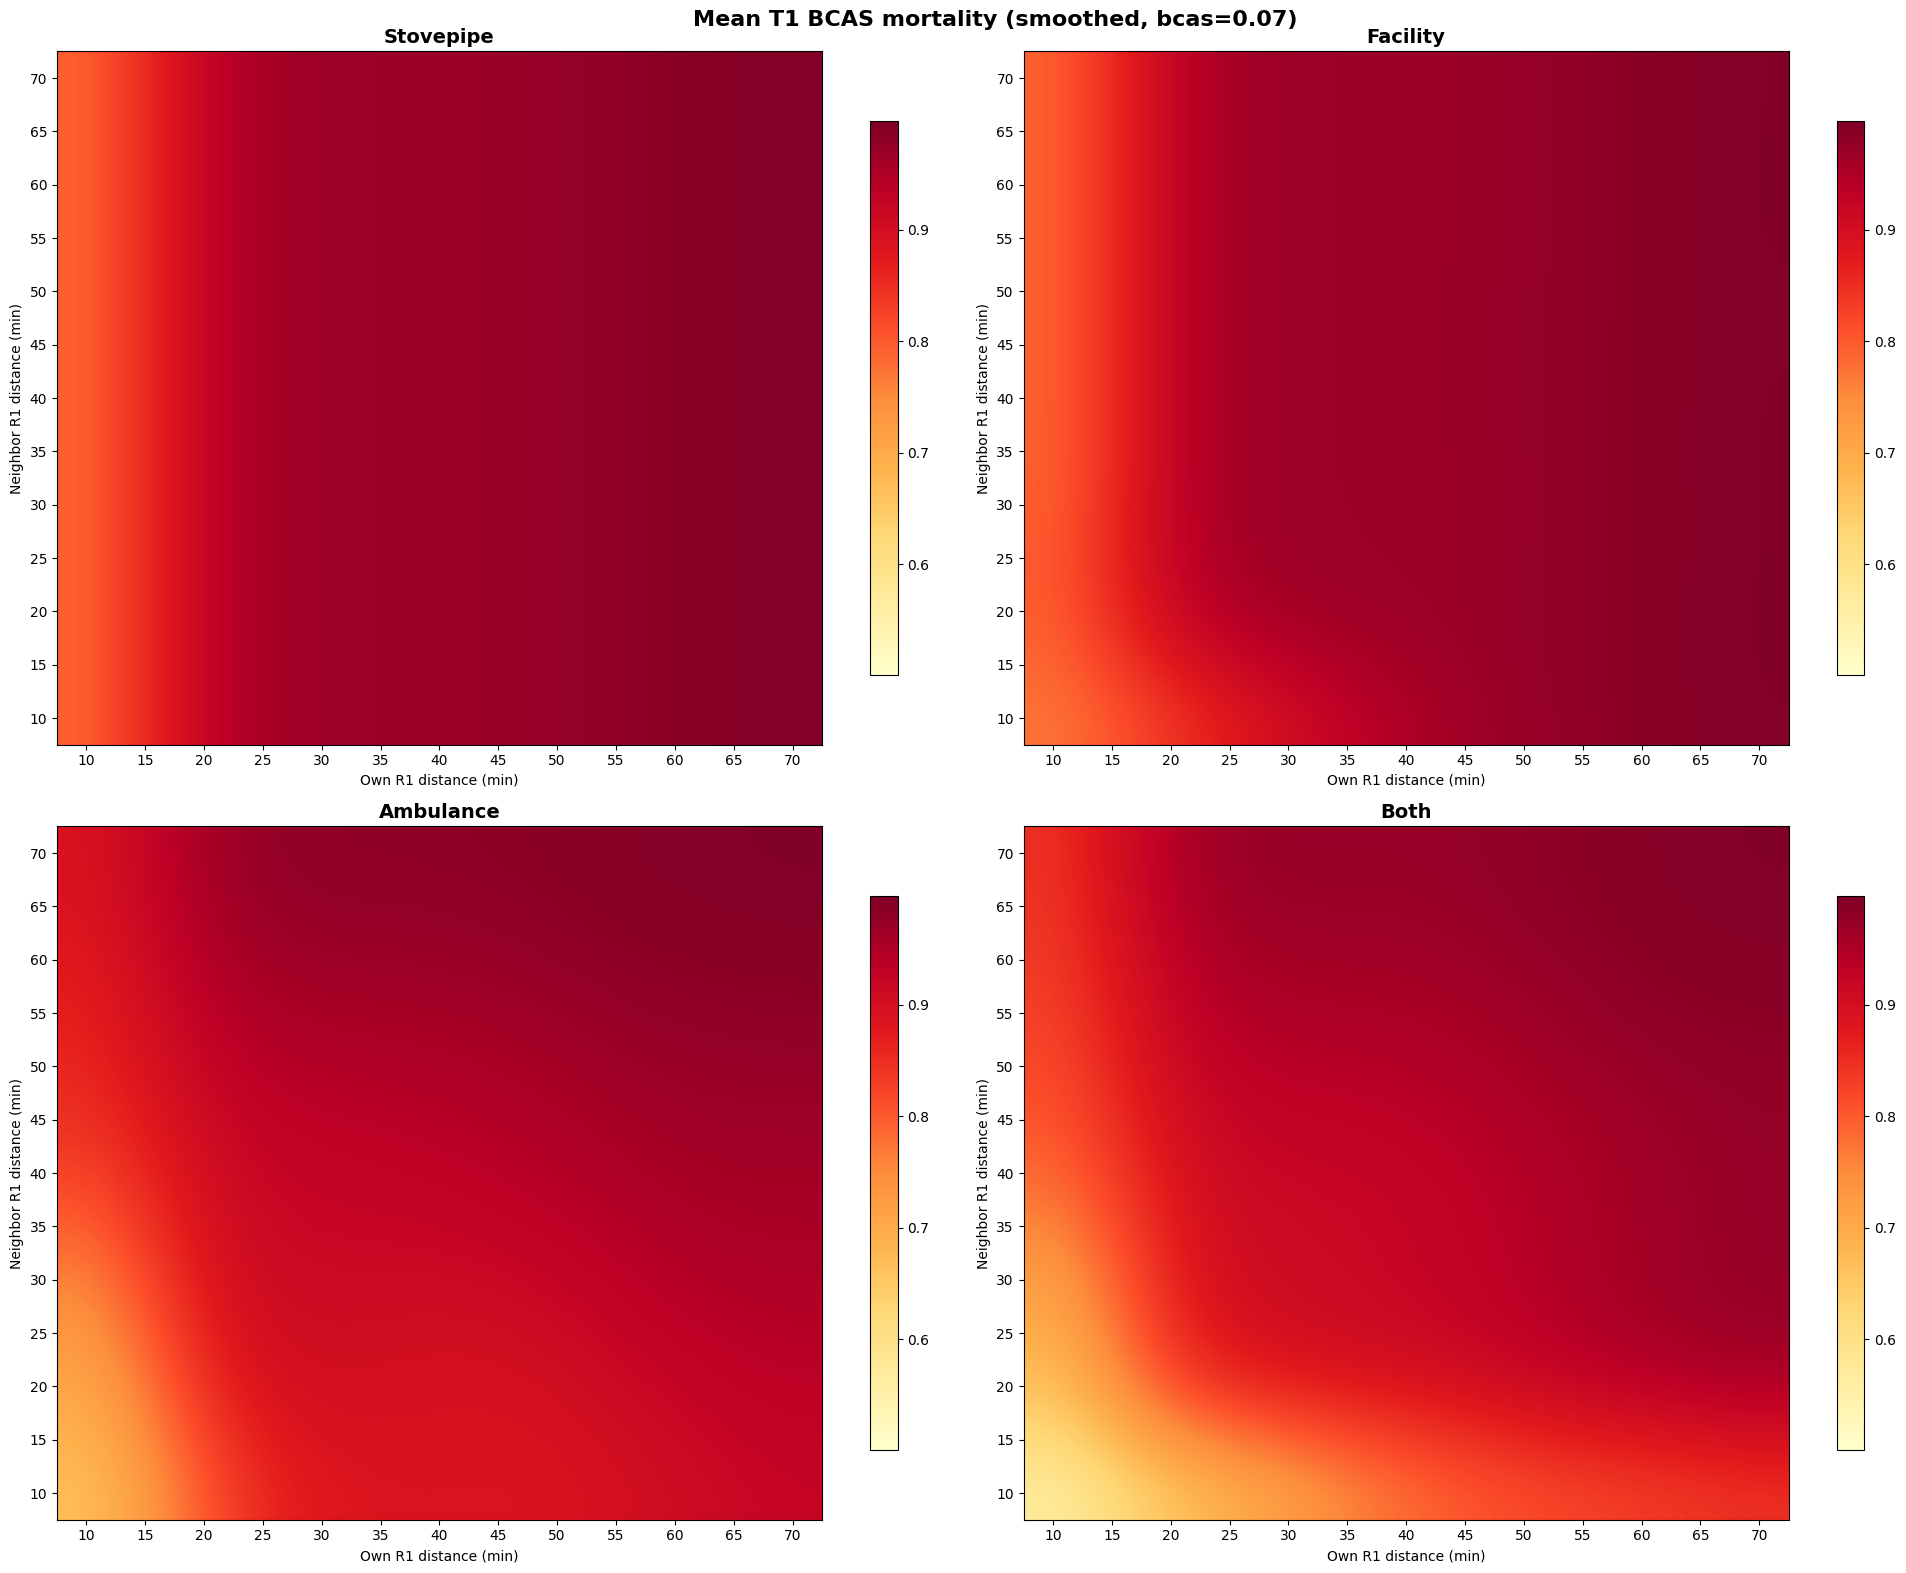

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(20, 16))

vmin = min(d.values.min() for d in data.values())
vmax = max(d.values.max() for d in data.values())

for ax, (label, pivot) in zip(axes.flat, data.items()):
    smoothed = gaussian_filter(pivot.values.astype(float), sigma=1.0)
    im = ax.imshow(smoothed, cmap="YlOrRd", origin="lower", aspect="auto",
                   interpolation="bicubic", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(cols)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(rows)
    ax.set_xlabel("Own R1 distance (min)")
    ax.set_ylabel("Neighbor R1 distance (min)")
    ax.set_title(label, fontsize=14, fontweight="bold")
    plt.colorbar(im, ax=ax, shrink=0.8)

plt.suptitle(f"Mean T1 BCAS mortality (smoothed, bcas={max_bcas})", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()


## Fraction of seeds where policy improves over stovepipe (delta < 0)


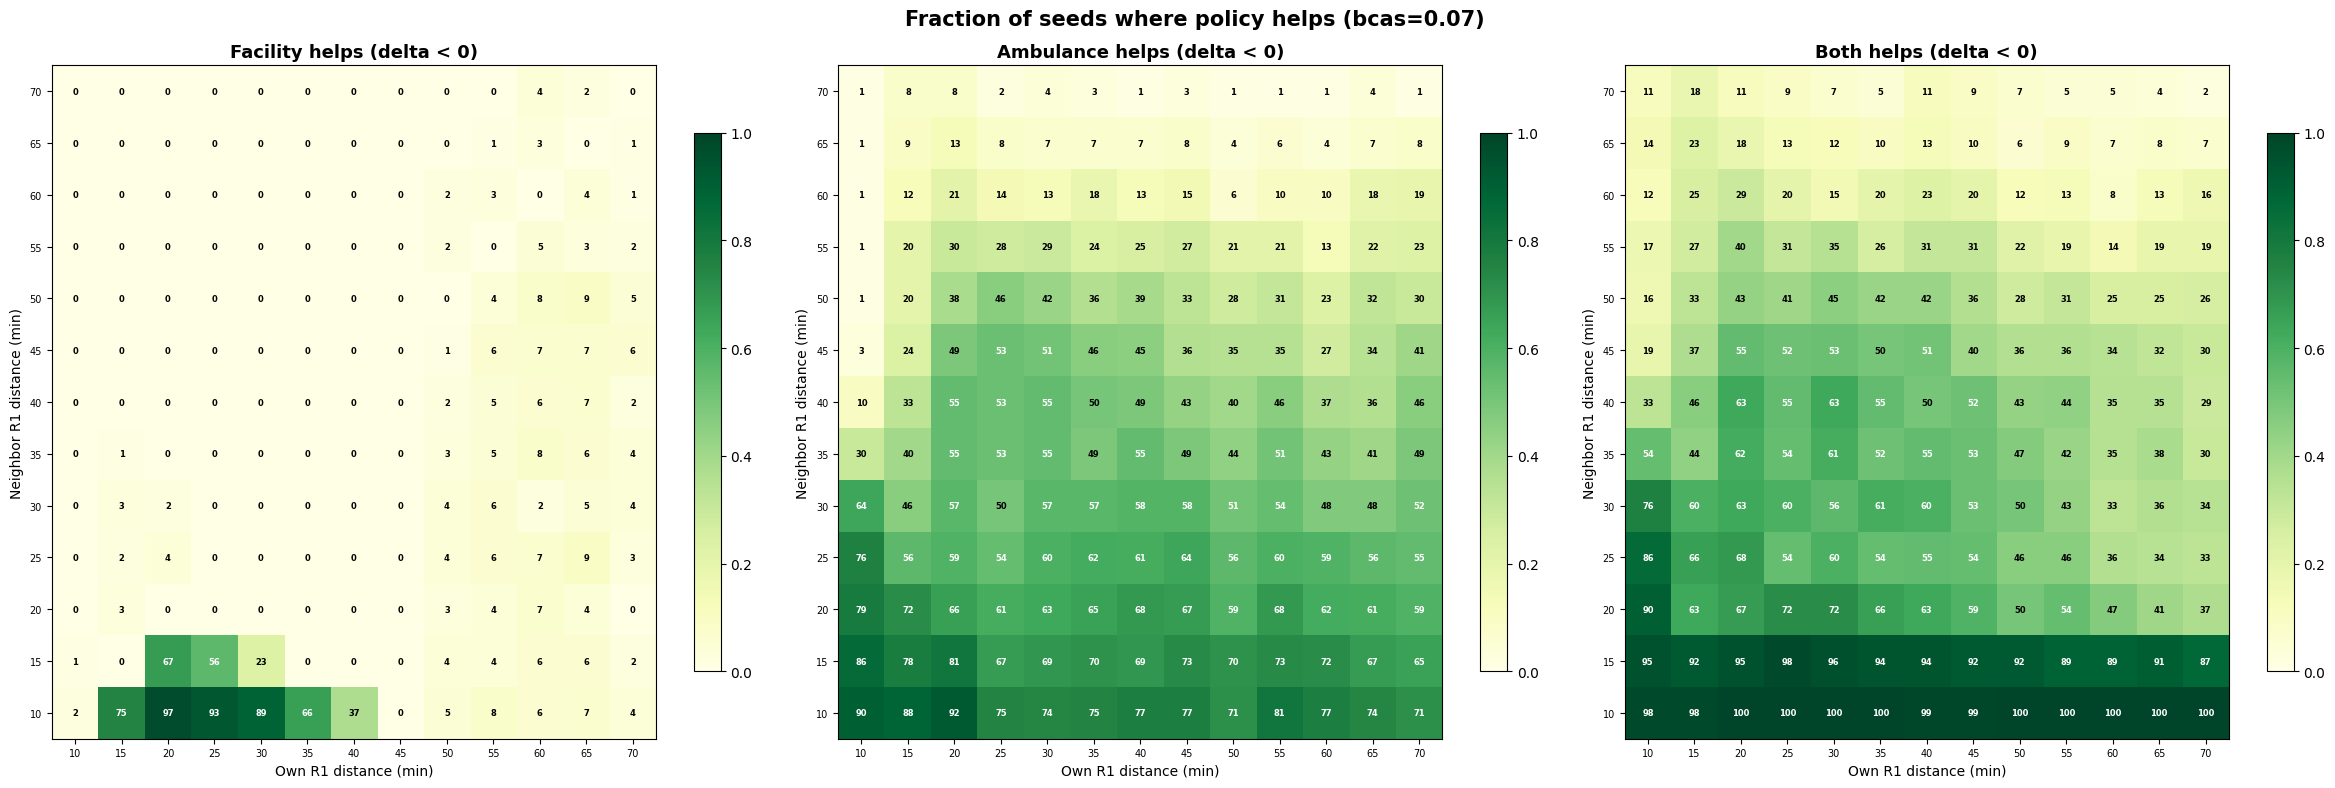

In [3]:
MATCH_COLS = ["seed", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]
stove_raw = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)]

pol_defs = [
    ("Facility", 1, 0),
    ("Ambulance", 0, 1),
    ("Both", 1, 1),
]

fig, axes = plt.subplots(1, 3, figsize=(24, 8))

for ax, (label, fac, amb) in zip(axes, pol_defs):
    pol_raw = df[(df["facility_eligibility"] == fac) & (df["ambulance_eligibility"] == amb)]

    merged = stove_raw[MATCH_COLS + ["death_rate_T1_BCAS"]].merge(
        pol_raw[MATCH_COLS + ["death_rate_T1_BCAS"]],
        on=MATCH_COLS, suffixes=("_stv", "_pol"))
    merged["delta"] = merged["death_rate_T1_BCAS_pol"] - merged["death_rate_T1_BCAS_stv"]
    merged["helps"] = merged["delta"] < 0

    grid = merged.groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]).agg(
        frac_helps=("helps", "mean"),
        n_helps=("helps", "sum"),
        n_total=("helps", "size"),
    ).reset_index()

    pivot_frac = grid.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="frac_helps")
    pivot_n = grid.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="n_helps")

    im = ax.imshow(pivot_frac.values, cmap="YlGn", origin="lower", aspect="auto",
                   interpolation="nearest", vmin=0, vmax=1)
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(cols, fontsize=7)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(rows, fontsize=7)
    ax.set_xlabel("Own R1 distance (min)")
    ax.set_ylabel("Neighbor R1 distance (min)")
    ax.set_title(f"{label} helps (delta < 0)", fontsize=13, fontweight="bold")

    for i in range(len(rows)):
        for j in range(len(cols)):
            frac = pivot_frac.values[i, j]
            n = int(pivot_n.values[i, j])
            color = "white" if frac > 0.5 else "black"
            ax.text(j, i, f"{n}", ha="center", va="center", fontsize=6, fontweight="bold", color=color)

    plt.colorbar(im, ax=ax, shrink=0.8)

plt.suptitle(f"Fraction of seeds where policy helps (bcas={max_bcas})", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()
